##  Diplomado en Ciencia de Datos

<h1 align = 'center'> MLflow: autolog, modelos y registro </h1>

En `13_MLflow_Tracking.ipynb` aprendimos a registrar *números* (parámetros y métricas) y archivos. Pero el producto final de un proyecto de ciencia de datos no es una tabla: es un **modelo** que alguien más pueda cargar y usar. Aquí veremos cómo MLflow nos ayuda a:

1. **Automatizar** el registro con `autolog`, y por qué conviene entender lo que registra.
2. Registrar cada combinación de una **búsqueda de hiperparámetros** (`GridSearchCV`, cuaderno 10).
3. **Comparar familias de modelos** con validación cruzada y elegir sin mirar el conjunto de prueba.
4. **Guardar el modelo** con su *firma* (qué columnas espera) y un ejemplo de entrada.
5. **Cargarlo** de nuevo y **evaluarlo** de forma estándar.
6. Añadir **interpretabilidad** (SHAP, cuaderno 11) como artefacto.
7. Versionar el modelo en el **Model Registry** con alias (`champion`).
8. **Servirlo** como una API REST con un solo comando.

El problema es el diagnóstico de cáncer de mama (`load_breast_cancer`), que ya conocemos de los cuadernos anteriores.

<h2 style="color: #007ACC;">Tabla de contenido</h2>

- [1. Datos y partición](#datos)
- [2. Autolog: registro automático](#autolog)
- [3. Búsqueda de hiperparámetros con autolog](#busqueda)
- [4. Comparar familias de modelos](#familias)
- [5. Guardar el modelo: firma y ejemplo de entrada](#guardar)
- [6. Cargar y evaluar el modelo](#cargar)
- [7. Interpretabilidad como artefacto](#shap)
- [8. Model Registry: versiones y alias](#registry)
- [9. Servir el modelo como API](#servir)
- [10. Ejercicios](#ejercicios)

<h2 style="color: #007ACC;">Instalación de librerías</h2>

Ejecuta esta celda si trabajas en Google Colab o en un entorno nuevo.

In [1]:
# Instalación de librerías necesarias para esta sesión
# (útil en Google Colab o en un entorno nuevo)
%pip install -q numpy pandas matplotlib scikit-learn mlflow shap

In [2]:
import warnings
warnings.filterwarnings('ignore')

import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

import mlflow
from mlflow import MlflowClient
from mlflow.models import infer_signature

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

os.environ['MLFLOW_ENABLE_ARTIFACTS_PROGRESS_BAR'] = 'false'   # menos ruido al descargar artefactos
print('MLflow', mlflow.__version__)

MLflow 3.17.2


<a id="datos"></a>
<h2 style="color: #007ACC;">1. Datos y partición</h2>

Dividimos **una sola vez** en entrenamiento y prueba, con estratificación. Toda decisión (hiperparámetros, familia de modelo) se tomará con validación cruzada *dentro del entrenamiento*; la prueba se usará **una vez**, al final, para el modelo elegido. Esta es la misma regla del proyecto final.

In [3]:
datos = load_breast_cancer(as_frame=True)
X, y = datos.data, datos.target            # 1 = benigno, 0 = maligno
SEMILLA = 42

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEMILLA)
print(f'Entrenamiento: {X_tr.shape} | Prueba: {X_te.shape} | Benignos: {y.mean():.1%}')

mlflow.set_tracking_uri('sqlite:///mlflow.db')

Entrenamiento: (426, 30) | Prueba: (143, 30) | Benignos: 62.7%


<a id="autolog"></a>
<h2 style="color: #007ACC;">2. Autolog: registro automático</h2>

En el cuaderno anterior escribimos a mano cada `log_param` y `log_metric`. Para las librerías más comunes, MLflow ofrece `autolog()`: se activa **una vez** y, a partir de ahí, cada `fit()` crea una corrida con los hiperparámetros del modelo, métricas de entrenamiento y el modelo mismo.

In [4]:
mlflow.set_experiment('cancer-autolog')
mlflow.sklearn.autolog(log_datasets=False, silent=True)

with mlflow.start_run(run_name='random-forest-autolog') as run:
    rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=SEMILLA).fit(X_tr, y_tr)

registrado = mlflow.get_run(run.info.run_id)
print('Parámetros registrados automáticamente:')
print(json.dumps({k: v for k, v in registrado.data.params.items() if k in ['n_estimators', 'max_depth', 'random_state', 'criterion', 'min_samples_leaf']}, indent=2))
print('\nMétricas:', registrado.data.metrics)

Parámetros registrados automáticamente:
{
  "criterion": "gini",
  "max_depth": "5",
  "min_samples_leaf": "1",
  "n_estimators": "100",
  "random_state": "42"
}

Métricas: {'training_precision_score': 0.9930359937402191, 'training_recall_score': 0.9929577464788732, 'training_f1_score': 0.9929438830375176, 'training_accuracy_score': 0.9929577464788732, 'training_log_loss': 0.048887017754470366, 'training_roc_auc': 0.9995760016959931, 'training_score': 0.9929577464788732}


Sin escribir un solo `log_param` quedaron registrados **todos** los hiperparámetros del bosque (los que dejamos por defecto también) y las métricas *de entrenamiento*. Ventajas e inconvenientes:

| Ventaja | Cuidado |
|---|---|
| Cero esfuerzo y no se olvida ningún hiperparámetro | Las métricas automáticas son sobre el **entrenamiento**: un bosque dará ≈1.0 y no dice nada sobre generalización |
| Guarda también el modelo y sus dependencias | No sabe qué semilla de la **partición** usaste, ni de qué datos vienen `X_tr` y `X_te`: eso lo debes registrar tú |
| Funciona con `GridSearchCV` y `Pipeline` | Genera mucho ruido si se activa en un cuaderno con muchos `fit()` exploratorios |

La recomendación: **autolog para lo mecánico, `log_*` explícito para lo que importa** (datos, semilla de partición, métrica de validación y de prueba).

<a id="busqueda"></a>
<h2 style="color: #007ACC;">3. Búsqueda de hiperparámetros con autolog</h2>

En `10_Validaciones.ipynb` usamos `GridSearchCV` y miramos el mejor resultado. Con autolog, **cada combinación probada queda como una corrida hija** de la búsqueda, con su puntaje de validación cruzada.

Por defecto autolog solo registra las 5 mejores combinaciones (`max_tuning_runs=5`); lo cambiamos a `None` para registrar todas. Desactivamos `log_models` aquí para no guardar un modelo por combinación.

In [5]:
mlflow.sklearn.autolog(log_models=False, log_datasets=False, max_tuning_runs=None, silent=True)
mlflow.set_experiment('cancer-busqueda-svm')

cuadricula = {'svc__C': [0.1, 1, 10, 100],
              'svc__gamma': [0.0001, 0.001, 0.01, 0.1],
              'svc__kernel': ['rbf']}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
busqueda = GridSearchCV(make_pipeline(StandardScaler(), SVC()), cuadricula, cv=cv, scoring='average_precision')

with mlflow.start_run(run_name='GridSearch SVM RBF') as padre:
    mlflow.log_params({'semilla_particion': SEMILLA, 'cv': '5-fold estratificado', 'metrica': 'average_precision'})
    busqueda.fit(X_tr, y_tr)

print('Mejor combinación:', busqueda.best_params_, '| PR-AUC en validación cruzada:', round(busqueda.best_score_, 4))

Mejor combinación: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'} | PR-AUC en validación cruzada: 0.9981


Abre la interfaz (`mlflow ui --backend-store-uri sqlite:///mlflow.db`) y entra al experimento `cancer-busqueda-svm`: verás la corrida padre con 16 hijas. Desde Python:

In [6]:
hijas = mlflow.search_runs(experiment_names=['cancer-busqueda-svm'],
                           filter_string=f"tags.mlflow.parentRunId = '{padre.info.run_id}'")
print(len(hijas), 'combinaciones registradas')
hijas.filter(regex='params.svc__(C|gamma)$|metrics.mean_test_score|metrics.rank_test_score').head(3)

16 combinaciones registradas


,metrics.mean_test_score,metrics.rank_test_score,params.svc__C,params.svc__gamma
0,0.992440,10.0,1,0.1
1,0.996229,6.0,100,0.01
2,0.991464,11.0,0.1,0.0001


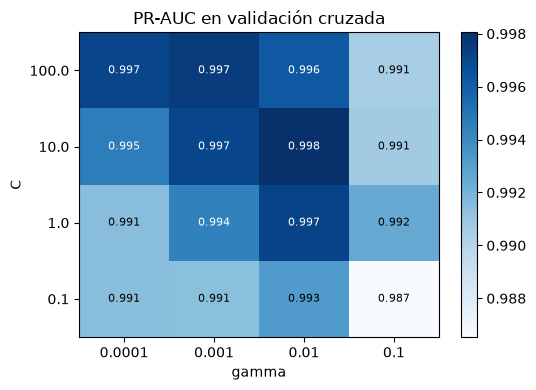

In [7]:
tabla = (hijas.assign(C=hijas['params.svc__C'].astype(float), gamma=hijas['params.svc__gamma'].astype(float))
              .pivot(index='C', columns='gamma', values='metrics.mean_test_score').sort_index(ascending=False))

fig, ax = plt.subplots(figsize=(5.5, 4))
im = ax.imshow(tabla.values, cmap='Blues', aspect='auto')
ax.set_xticks(range(tabla.shape[1]), tabla.columns); ax.set_yticks(range(tabla.shape[0]), tabla.index)
ax.set_xlabel('gamma'); ax.set_ylabel('C'); ax.set_title('PR-AUC en validación cruzada')
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        ax.text(j, i, f'{tabla.values[i, j]:.3f}', ha='center', va='center', fontsize=8,
                color='white' if tabla.values[i, j] > tabla.values.mean() else 'black')
fig.colorbar(im); plt.tight_layout()

# Guardamos el mapa de calor en la corrida padre (se puede reabrir una corrida con su ID)
with mlflow.start_run(run_id=padre.info.run_id):
    mlflow.log_figure(fig, 'mapa_calor_busqueda.png')

Dos ideas nuevas en la última celda: (1) las **hijas** se consultan filtrando por `mlflow.parentRunId`, y (2) una corrida ya terminada se puede **reabrir** con `start_run(run_id=...)` para añadirle artefactos o etiquetas después.

<a id="familias"></a>
<h2 style="color: #007ACC;">4. Comparar familias de modelos</h2>

Ahora comparamos tres familias con la **misma validación cruzada** y la misma métrica. Aquí registramos a mano (sin autolog) porque queremos controlar exactamente qué se guarda: la media y la desviación del puntaje de validación, **no** métricas de prueba.

In [8]:
mlflow.sklearn.autolog(disable=True)
mlflow.set_experiment('cancer-familias')

familias = {
    'Regresión logística': make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)),
    'SVM RBF':             make_pipeline(StandardScaler(), SVC(**{k.split('__')[1]: v for k, v in busqueda.best_params_.items()}, probability=True)),
    'Random Forest':       RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEMILLA),
    'Gradient Boosting':   HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, random_state=SEMILLA),
}

for nombre, modelo in familias.items():
    with mlflow.start_run(run_name=nombre):
        mlflow.log_params({'familia': nombre, 'semilla_particion': SEMILLA, 'cv': '5-fold estratificado'})
        mlflow.log_params({f'hp_{k}': v for k, v in modelo.get_params(deep=False).items() if isinstance(v, (int, float, str)) or v is None})
        res = cross_validate(modelo, X_tr, y_tr, cv=cv, scoring=['average_precision', 'roc_auc', 'f1'])
        for m in ['average_precision', 'roc_auc', 'f1']:
            mlflow.log_metrics({f'cv_{m}_media': res[f'test_{m}'].mean(), f'cv_{m}_std': res[f'test_{m}'].std()})

(mlflow.search_runs(experiment_names=['cancer-familias'], order_by=['metrics.cv_average_precision_media DESC'])
       [['params.familia', 'metrics.cv_average_precision_media', 'metrics.cv_average_precision_std', 'metrics.cv_roc_auc_media', 'metrics.cv_f1_media']]
       .rename(columns=lambda c: c.split('.')[-1]).round(4))

,familia,cv_average_precision_media,cv_average_precision_std,cv_roc_auc_media,cv_f1_media
0,SVM RBF,0.9981,0.0027,0.9971,0.9780
1,Regresión logística,0.9974,0.0029,0.9962,0.9833
2,Random Forest,0.9912,0.0091,0.9889,0.9644
3,Gradient Boosting,0.9876,0.0153,0.9872,0.9661


Las diferencias son pequeñas frente a la desviación entre pliegues: en un problema tan "fácil" varias familias empatan técnicamente. Elegiremos la **regresión logística**: empata en rendimiento y es la más simple e interpretable (principio de parsimonia). Lo importante es que **la elección quedó justificada con validación, no con prueba**.

<a id="guardar"></a>
<h2 style="color: #007ACC;">5. Guardar el modelo: firma y ejemplo de entrada</h2>

Ahora entrenamos el modelo elegido con **todo el entrenamiento** y lo guardamos como artefacto de la corrida con `mlflow.sklearn.log_model`. Registramos dos cosas más que nos ahorrarán problemas:

- La **firma** (*signature*): los nombres y tipos de las columnas de entrada y la forma de la salida. MLflow la usa para validar que quien llama al modelo envíe los datos correctos.
- Un **ejemplo de entrada** (*input example*): unas filas reales para probar el modelo y para documentarlo.

Por defecto, la interfaz genérica `pyfunc` expone el método `predict` (la clase). Como aquí nos interesa la **probabilidad**, indicamos `pyfunc_predict_fn='predict_proba'` y firmamos con ese mismo tipo de salida.

Guardamos el **pipeline completo** (escalado + modelo): así quien lo cargue envía datos *crudos* y no puede olvidar o duplicar el escalado, un error clásico de fuga de información.

In [9]:
modelo_final = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000)).fit(X_tr, y_tr)

firma = infer_signature(X_tr, modelo_final.predict_proba(X_tr))
ejemplo = X_tr.head(3)

mlflow.set_experiment('cancer-modelo-final')
with mlflow.start_run(run_name='regresion-logistica-final') as run_final:
    mlflow.log_params({'familia': 'Regresión logística', 'C': 1.0, 'semilla_particion': SEMILLA,
                       'seleccion': 'validación cruzada 5-fold (average_precision)'})
    mlflow.set_tag('etapa', 'final')

    # La prueba se evalúa UNA vez, con el modelo ya elegido
    p_te = modelo_final.predict_proba(X_te)[:, 1]
    mlflow.log_metrics({'test_roc_auc': roc_auc_score(y_te, p_te),
                        'test_pr_auc': average_precision_score(y_te, p_te),
                        'test_f1': f1_score(y_te, p_te >= 0.5)})

    info = mlflow.sklearn.log_model(modelo_final, name='modelo', signature=firma, input_example=ejemplo,
                                    pyfunc_predict_fn='predict_proba')

print('URI del modelo:', info.model_uri)
print('Entradas:', len(firma.inputs.inputs), 'columnas numéricas (double), todas obligatorias')
print('Salida  :', firma.outputs)

URI del modelo: models:/m-ede55ac7fc7d4863961b2c267c51a4fc
Entradas: 30 columnas numéricas (double), todas obligatorias
Salida  : [Tensor('float64', (-1, 2))]


Al guardar un modelo, MLflow crea una carpeta autocontenida con el modelo serializado, la lista de dependencias y un archivo `MLmodel` que describe cómo cargarlo. Veámoslo:

In [10]:
carpeta = mlflow.artifacts.download_artifacts(run_id=run_final.info.run_id, artifact_path='modelo')
print(sorted(os.listdir(carpeta)), '\n')
print(''.join(l for l in open(os.path.join(carpeta, 'MLmodel')) if not l.startswith('artifact_path')))

['MLmodel', 'conda.yaml', 'input_example.json', 'model.skops', 'python_env.yaml', 'registered_model_meta', 'requirements.txt', 'serving_input_example.json'] 

flavors:
  python_function:
    env:
      conda: conda.yaml
      virtualenv: python_env.yaml
    loader_module: mlflow.sklearn
    model_path: model.skops
    predict_fn: predict_proba
    python_version: 3.12.3
  sklearn:
    code: null
    pickled_model: model.skops
    serialization_format: skops
    sklearn_version: 1.9.1
    skops_trusted_types: null
is_signature_from_type_hint: false
mlflow_version: 3.17.2
model_id: m-ede55ac7fc7d4863961b2c267c51a4fc
model_size_bytes: 39834
model_uuid: m-ede55ac7fc7d4863961b2c267c51a4fc
prompts: null
run_id: 05786ec00eb54791a27dca27eab121c1
saved_input_example_info:
  artifact_path: input_example.json
  pandas_orient: split
  serving_input_path: serving_input_example.json
  type: dataframe
signature:
  inputs: '[{"type": "double", "name": "mean radius", "required": true}, {"type":
    "do

El archivo `MLmodel` declara varios **sabores** (*flavors*): el modelo se puede cargar como `sklearn` (con todos sus métodos) o como `python_function` (`pyfunc`), una interfaz genérica de "recibe una tabla, devuelve predicciones" que es igual para scikit-learn, Keras, XGBoost, etc. Esa uniformidad es lo que permite servir cualquier modelo del mismo modo.

<a id="cargar"></a>
<h2 style="color: #007ACC;">6. Cargar y evaluar el modelo</h2>

In [11]:
# Sabor genérico: pyfunc
modelo_py = mlflow.pyfunc.load_model(info.model_uri)
print('pyfunc  [P(maligno), P(benigno)]:', np.round(modelo_py.predict(X_te.head(3)), 4).tolist())

# Sabor nativo: recuperamos el pipeline de scikit-learn completo
modelo_sk = mlflow.sklearn.load_model(info.model_uri)
print('sklearn [P(maligno), P(benigno)]:', np.round(modelo_sk.predict_proba(X_te.head(3)), 4).tolist())

pyfunc  [P(maligno), P(benigno)]: [[0.031, 0.969], [0.9996, 0.0004], [0.4406, 0.5594]]
sklearn [P(maligno), P(benigno)]: [[0.031, 0.969], [0.9996, 0.0004], [0.4406, 0.5594]]


Ambos dan lo mismo; `pyfunc` devuelve lo que la firma declaró (las probabilidades, por `pyfunc_predict_fn`), y el sabor `sklearn` conserva todos los métodos del pipeline. Un detalle útil: como la firma exige las 30 columnas con sus nombres y tipos, si enviamos una tabla mal formada MLflow falla **con un mensaje claro** en lugar de entregar un resultado sin sentido:

In [12]:
try:
    modelo_py.predict(X_te.drop(columns=['mean radius']).head(3))
except Exception as e:
    print(type(e).__name__, '->', str(e).split('Error: ')[-1])

MlflowException -> Model is missing inputs ['mean radius'].


<h3 style="color: #007ACC;">Evaluación estándar con mlflow.models.evaluate</h3>

MLflow puede evaluar un modelo guardado sobre un conjunto de datos y registrar **automáticamente** las métricas y los gráficos habituales de clasificación (matriz de confusión, curvas ROC, PR, de calibración y de *lift*) en una corrida. Desactivamos su explicación SHAP automática porque la haremos nosotros en la siguiente sección:

In [13]:
datos_eval = X_te.assign(objetivo=y_te)
with mlflow.start_run(run_id=run_final.info.run_id):
    evaluacion = mlflow.models.evaluate(info.model_uri, datos_eval, targets='objetivo', model_type='classifier',
                                         evaluator_config={'log_model_explainability': False, 'metric_prefix': 'eval_'})

pd.Series(evaluacion.metrics).round(4).head(12)

eval_score                0.9860
eval_true_negatives      52.0000
eval_false_positives      1.0000
eval_false_negatives      1.0000
eval_true_positives      89.0000
eval_example_count      143.0000
eval_accuracy_score       0.9860
eval_recall_score         0.9889
eval_precision_score      0.9889
eval_f1_score             0.9889
eval_log_loss             0.0679
eval_roc_auc              0.9977
dtype: float64

<Figure size 1050x700 with 0 Axes>

In [14]:
print(sorted(evaluacion.artifacts)[:8])

['calibration_curve_plot', 'confusion_matrix', 'lift_curve_plot', 'precision_recall_curve_plot', 'roc_curve_plot']


<a id="shap"></a>
<h2 style="color: #007ACC;">7. Interpretabilidad como artefacto</h2>

En `11_SHAP.ipynb` vimos valores SHAP para explicar un modelo. Un modelo desplegado sin su explicación es difícil de auditar, así que la guardamos junto a él. Para una regresión logística, `shap.LinearExplainer` es exacto y rápido.

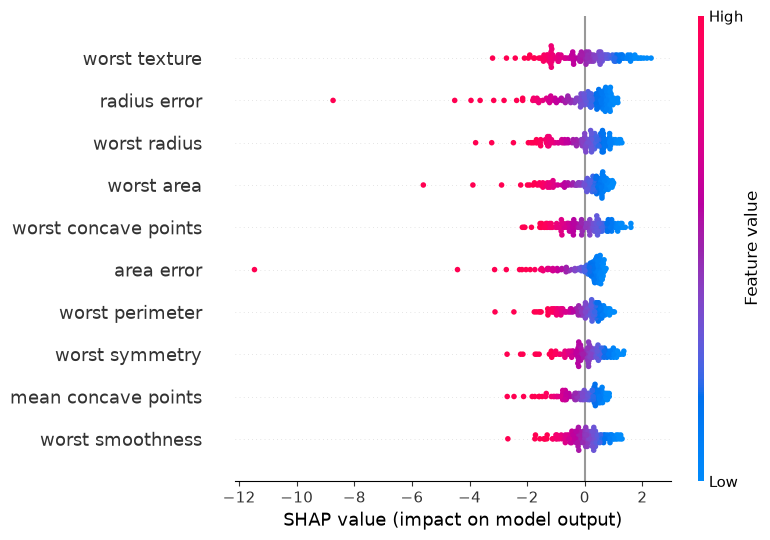

In [15]:
import shap

escalador, clasificador = modelo_final[0], modelo_final[-1]
X_tr_esc = pd.DataFrame(escalador.transform(X_tr), columns=X_tr.columns)
X_te_esc = pd.DataFrame(escalador.transform(X_te), columns=X_te.columns)

explicador = shap.LinearExplainer(clasificador, shap.maskers.Independent(X_tr_esc, max_samples=len(X_tr_esc)))
valores = explicador(X_te_esc)

shap.summary_plot(valores, X_te_esc, max_display=10, show=False)
fig = plt.gcf(); plt.tight_layout()

with mlflow.start_run(run_id=run_final.info.run_id):
    mlflow.log_figure(fig, 'shap_resumen.png')
    importancias = pd.Series(np.abs(valores.values).mean(axis=0), index=X_te.columns).nlargest(10)
    mlflow.log_dict(importancias.round(4).to_dict(), 'shap_top10.json')

Recuerda que en este conjunto `1 = benigno`: valores **altos** de `worst texture` o `radius error` (puntos rojos a la izquierda) empujan la predicción hacia *maligno*, lo que concuerda con la clínica. 

El modelo, sus métricas de prueba, la evaluación y su explicación viven ahora **en una sola corrida**. Una persona que audite el modelo dentro de seis meses encontrará todo en el mismo lugar.

<a id="registry"></a>
<h2 style="color: #007ACC;">8. Model Registry: versiones y alias</h2>

Las corridas son un historial de *experimentos*; el **Model Registry** es el catálogo de los modelos que *efectivamente usamos*. Registrar un modelo le da un **nombre estable** y un **número de versión**; así, "el modelo de cáncer en producción" deja de ser "la corrida `3f2a…`".

En lugar de las antiguas etapas (*Staging*/*Production*, ya obsoletas), hoy se usan **alias**: etiquetas movibles como `champion` (el que se usa) o `challenger` (el candidato). Quien consume el modelo pide `models:/nombre@champion` y no se entera de qué versión es.

In [16]:
NOMBRE = 'clasificador_cancer'
cliente = MlflowClient()

v1 = mlflow.register_model(info.model_uri, NOMBRE)
cliente.set_registered_model_alias(NOMBRE, 'champion', v1.version)
cliente.set_model_version_tag(NOMBRE, v1.version, 'validado_por', 'validación cruzada 5-fold')

print(f'Versión {v1.version} registrada con el alias champion')

Versión 1 registrada con el alias champion


Quien use el modelo lo carga **por alias**:

In [17]:
produccion = mlflow.pyfunc.load_model(f'models:/{NOMBRE}@champion')
print('[P(maligno), P(benigno)] para 3 filas:', np.round(produccion.predict(X_te.head(3)), 3).tolist())

[P(maligno), P(benigno)] para 3 filas: [[0.031, 0.969], [1.0, 0.0], [0.441, 0.559]]


> **Una nota de seguridad.** Por defecto `log_model` serializa los modelos de scikit-learn con el formato `skops`, que (a diferencia de `pickle`) **revisa qué tipos de objetos contiene el archivo** antes de cargarlo, porque un `pickle` malicioso puede ejecutar código arbitrario al abrirlo. La regresión logística usa solo tipos conocidos, pero los modelos basados en árboles contienen un objeto interno (`sklearn.tree._tree.Tree`) que `skops` no da por confiable automáticamente: al guardarlo hay que **declararlo explícitamente** con `skops_trusted_types`, como hacemos abajo. Es una buena práctica: *nunca cargues un modelo de una fuente que no conozcas*.

Ahora simulamos un ciclo de vida real: entrenamos un **candidato** (un bosque aleatorio), lo registramos como versión 2 y lo comparamos con el actual. Si fuera mejor, bastaría **mover el alias** y los consumidores recibirían el nuevo modelo sin cambiar una línea de código; si no, se queda como `challenger`.

In [18]:
candidato = make_pipeline(StandardScaler(), RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEMILLA)).fit(X_tr, y_tr)

with mlflow.start_run(run_name='random-forest-candidato'):
    mlflow.set_tag('etapa', 'candidato')
    info2 = mlflow.sklearn.log_model(candidato, name='modelo', signature=infer_signature(X_tr, candidato.predict_proba(X_tr)),
                                     input_example=ejemplo, pyfunc_predict_fn='predict_proba',
                                     skops_trusted_types=['sklearn.tree._tree.Tree'])
v2 = mlflow.register_model(info2.model_uri, NOMBRE)
cliente.set_registered_model_alias(NOMBRE, 'challenger', v2.version)

for alias in ['champion', 'challenger']:
    v = cliente.get_model_version_by_alias(NOMBRE, alias)
    print(f'{alias:10s} -> versión {v.version}')

champion   -> versión 1
challenger -> versión 2


In [19]:
# Decisión: ¿promovemos al challenger? Se decide con validación, no con prueba.
cv_champion = cross_validate(modelo_final, X_tr, y_tr, cv=cv, scoring='average_precision')['test_score']
cv_challenger = cross_validate(candidato, X_tr, y_tr, cv=cv, scoring='average_precision')['test_score']
print(f'champion  : {cv_champion.mean():.4f} ± {cv_champion.std():.4f}')
print(f'challenger: {cv_challenger.mean():.4f} ± {cv_challenger.std():.4f}')

if cv_challenger.mean() - cv_champion.mean() > cv_champion.std():
    cliente.set_registered_model_alias(NOMBRE, 'champion', v2.version)
    print('-> el challenger supera al champion por más de una desviación: se promueve')
else:
    print('-> la diferencia no supera la variabilidad entre pliegues: el champion se mantiene')

champion  : 0.9974 ± 0.0029
challenger: 0.9912 ± 0.0091
-> la diferencia no supera la variabilidad entre pliegues: el champion se mantiene


<a id="servir"></a>
<h2 style="color: #007ACC;">9. Servir el modelo como API</h2>

Como todo modelo guardado en MLflow tiene la interfaz `pyfunc`, se puede publicar como una **API REST** con un único comando, sin escribir código de servidor. En una **terminal**, en la carpeta del cuaderno:

```bash
mlflow models serve -m "models:/clasificador_cancer@champion" -p 5001 --env-manager local
```

(`--env-manager local` usa tu entorno actual; sin esa opción MLflow crea un entorno nuevo con las dependencias registradas, que es lo ideal en producción pero tarda más. Antes de ejecutarlo en una terminal nueva, define `export MLFLOW_TRACKING_URI=sqlite:///mlflow.db` para que encuentre el registro.)

Luego se hacen peticiones HTTP a `/invocations`. Generemos el cuerpo de la petición con tres pacientes de la muestra de prueba:

In [20]:
cuerpo = {'dataframe_split': json.loads(X_te.head(3).to_json(orient='split'))}
print(json.dumps(cuerpo)[:300], '...')

with open('peticion.json', 'w') as f:
    json.dump(cuerpo, f)

{"dataframe_split": {"columns": ["mean radius", "mean texture", "mean perimeter", "mean area", "mean smoothness", "mean compactness", "mean concavity", "mean concave points", "mean symmetry", "mean fractal dimension", "radius error", "texture error", "perimeter error", "area error", "smoothness erro ...


Y se consulta, por ejemplo, con `curl` desde otra terminal:

```bash
curl -s -X POST http://127.0.0.1:5001/invocations -H "Content-Type: application/json" -d @peticion.json
```

La respuesta es un JSON con las predicciones (`{"predictions": [[...], ...]}`). Cualquier aplicación (web, móvil, otro servicio) puede usar el modelo sin saber que detrás hay scikit-learn. Observa que el servidor **valida la firma**: si a la petición le falta una columna, devuelve un error claro.

<a id="ejercicios"></a>
<h2 style="color: #007ACC;">10. Ejercicios</h2>

1. **Autolog con `GridSearchCV`.** Repite la búsqueda de la sección 3 con un `RandomForestClassifier` (`n_estimators`, `max_depth`, `min_samples_leaf`). Con la tabla de `search_runs`, encuentra qué hiperparámetro tiene mayor efecto sobre `mean_test_score`.
2. **Registrar la partición.** Añade a la corrida de la sección 4 un `mlflow.log_input` con `mlflow.data.from_pandas(X_tr, targets=...)`. ¿Qué cambia en la interfaz?
3. **Firma estricta.** Intenta consultar el modelo con una columna de texto en lugar de numérica. ¿Qué error obtienes? ¿Qué pasaría sin firma?
4. **Otro artefacto.** Registra en la corrida final la matriz de confusión **al umbral que maximiza el $F_1$ en validación** (no en prueba). Recuerda el cuaderno 12.
5. **Ciclo de vida.** Registra una tercera versión con `HistGradientBoostingClassifier`, ponle alias `challenger` y decide si se promueve. Luego haz una **reversión**: mueve `champion` de vuelta a la versión 1 y comprueba que `models:/clasificador_cancer@champion` devuelve el modelo anterior.
6. **Servir.** Levanta el servidor, consulta con `curl` y con `requests` desde Python, y compara las predicciones con `modelo_py.predict`. ¿Coinciden exactamente?
7. **Reflexión.** Un colega propone elegir el modelo con la métrica `test_pr_auc` más alta entre las 20 corridas del experimento. ¿Qué problema tiene esa estrategia? ¿Cómo ayuda la estructura de experimentos de este cuaderno a evitarla?